# 8. Transfer: small reservoirs the models never saw

The Highland Lakes are gauged every day, so a satellite map there mostly confirms the gauge
(notebook 7). The case where satellite mapping would be **useful** is a reservoir with no gauge.
Texas has thousands of small reservoirs and ponds, and only about 120 appear in TWDB's daily
record.

But a truly ungauged reservoir has nothing to score against. So this test uses the next best
thing: **pseudo-ungauged** reservoirs. They have a TWDB record, but we map them exactly as if
they didn't:

* The models are the shipped ones, trained only on Highland Lakes imagery. No retraining and no
  fine-tuning.
* NDWI, MNDWI and VV cutoffs are the medians of the cutoffs tuned on the Highland Lakes hand
  labels (NDWI −0.025, MNDWI −0.14, VV −14.2 dB). Nothing is tuned on the new lakes.
  Per-scene Otsu cutoffs (fully unsupervised) are also reported.
* The lake zone comes from the JRC water history around TWDB's published location point.
* The TWDB record is opened **only afterwards**, to score the maps.

One consequence matters for how we score. On a gauged lake you can calibrate satellite area
against the gauge (the "after linear fit" numbers in notebook 7). On an ungauged lake you
can't, so **raw error is what a user would get**, and that is the headline metric here.

In [1]:
from hlw.nb import BLUE, GREEN, GREY, INK, ORANGE, setup

setup()
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hlw import levels, transfer
from hlw import config as C

L = transfer.lakes()
cfg = transfer.tcfg()
rows = []
for k, lake in L.items():
    lv = levels.load(k)
    rows.append({"lake": lake.name, "TWDB max area (ac)": lv.surface_area.max(),
                 "min area (ac)": lv.surface_area.min(),
                 "swing": f"{1 - lv.surface_area.min() / lv.surface_area.max():.0%}",
                 "lon, lat": f"{lake.seed[0]:.3f}, {lake.seed[1]:.3f}"})
sites = pd.DataFrame(rows).sort_values("TWDB max area (ac)")
sites.round(0)

,lake,TWDB max area (ac),min area (ac),swing,"lon, lat"
0,Mackenzie Reservoir,285.0,152.0,46%,"-101.438, 34.545"
1,Hords Creek Lake,489.0,165.0,66%,"-99.561, 31.833"
3,Lake Sweetwater,657.0,180.0,73%,"-100.304, 32.439"
2,Lake Abilene,664.0,90.0,86%,"-99.889, 32.235"
4,Greenbelt Lake,781.0,265.0,66%,"-100.895, 35.001"
5,O. C. Fisher Lake,1802.0,284.0,84%,"-100.482, 31.485"
6,Brady Creek Reservoir,2177.0,848.0,61%,"-99.386, 31.138"
7,Oak Creek Reservoir,2595.0,507.0,80%,"-100.268, 32.041"
8,Medina Lake,6084.0,479.0,92%,"-98.934, 29.540"
9,Twin Buttes Reservoir,7239.0,915.0,87%,"-100.538, 31.382"


## Why these ten

They were chosen from the 122 reservoirs in TWDB's statewide list by four rules, all fixed
before mapping:

1. **Small.** Maximum area 2018-2026 between about 300 and 7,000 acres, against 6,000-25,000
   for the Highland Lakes' big two. The smallest, Mackenzie, is about 1 km² of water.
2. **A real signal.** Area swung by at least 45 % over the period, so there is change to track.
3. **A complete record.** At least 99 % of days have a TWDB area value.
4. **A different setting.** Semi-arid West and Central Texas plains and plateau: red-clay
   turbid water, shallow basins that expose wide mudflats (Twin Buttes, O.C. Fisher), and
   narrow canyon lakes (Mackenzie, Medina). The training lakes are clear Hill Country
   limestone reservoirs.

Rule 4 makes this a harder test than "more of the same". If the model only learned what the
Highland Lakes look like, it should fail here.

## What the maps look like

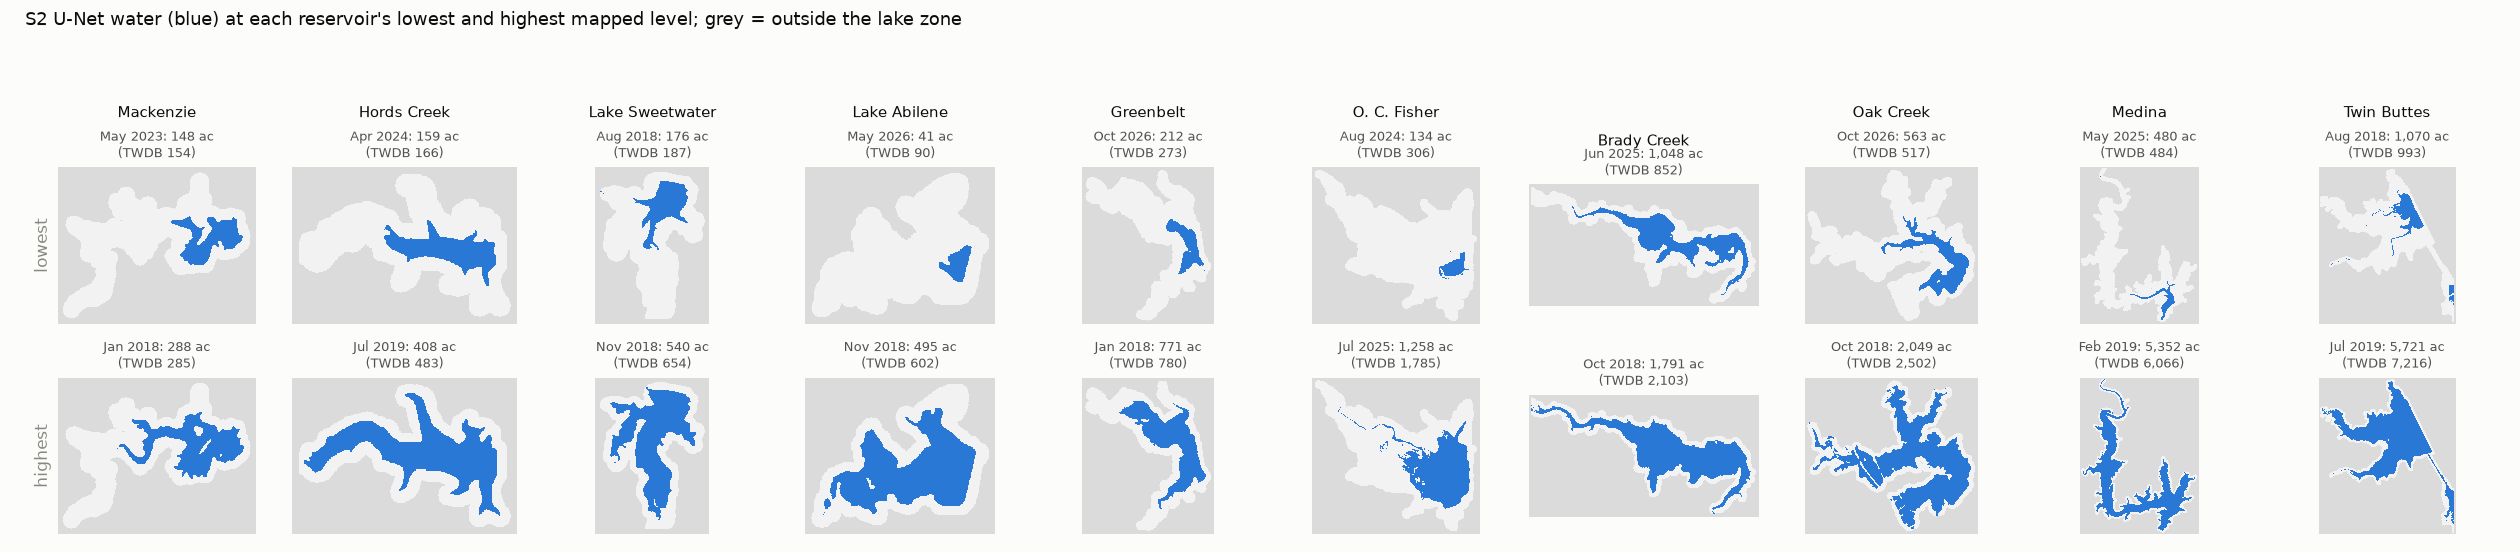

In [2]:
from IPython.display import Image, display

display(Image(filename=str(C.RESULTS_DIR / "transfer" / "transfer_maps.png"), width=1100))

Each reservoir at its lowest and highest mapped level. The lake zone (white plus blue) is the
JRC 1984-2020 water extent plus a 150 m buffer; blue is what the S2 U-Net called water that day.
Several of these lakes shrank to a fraction of their zone during the 2022-2024 drought.

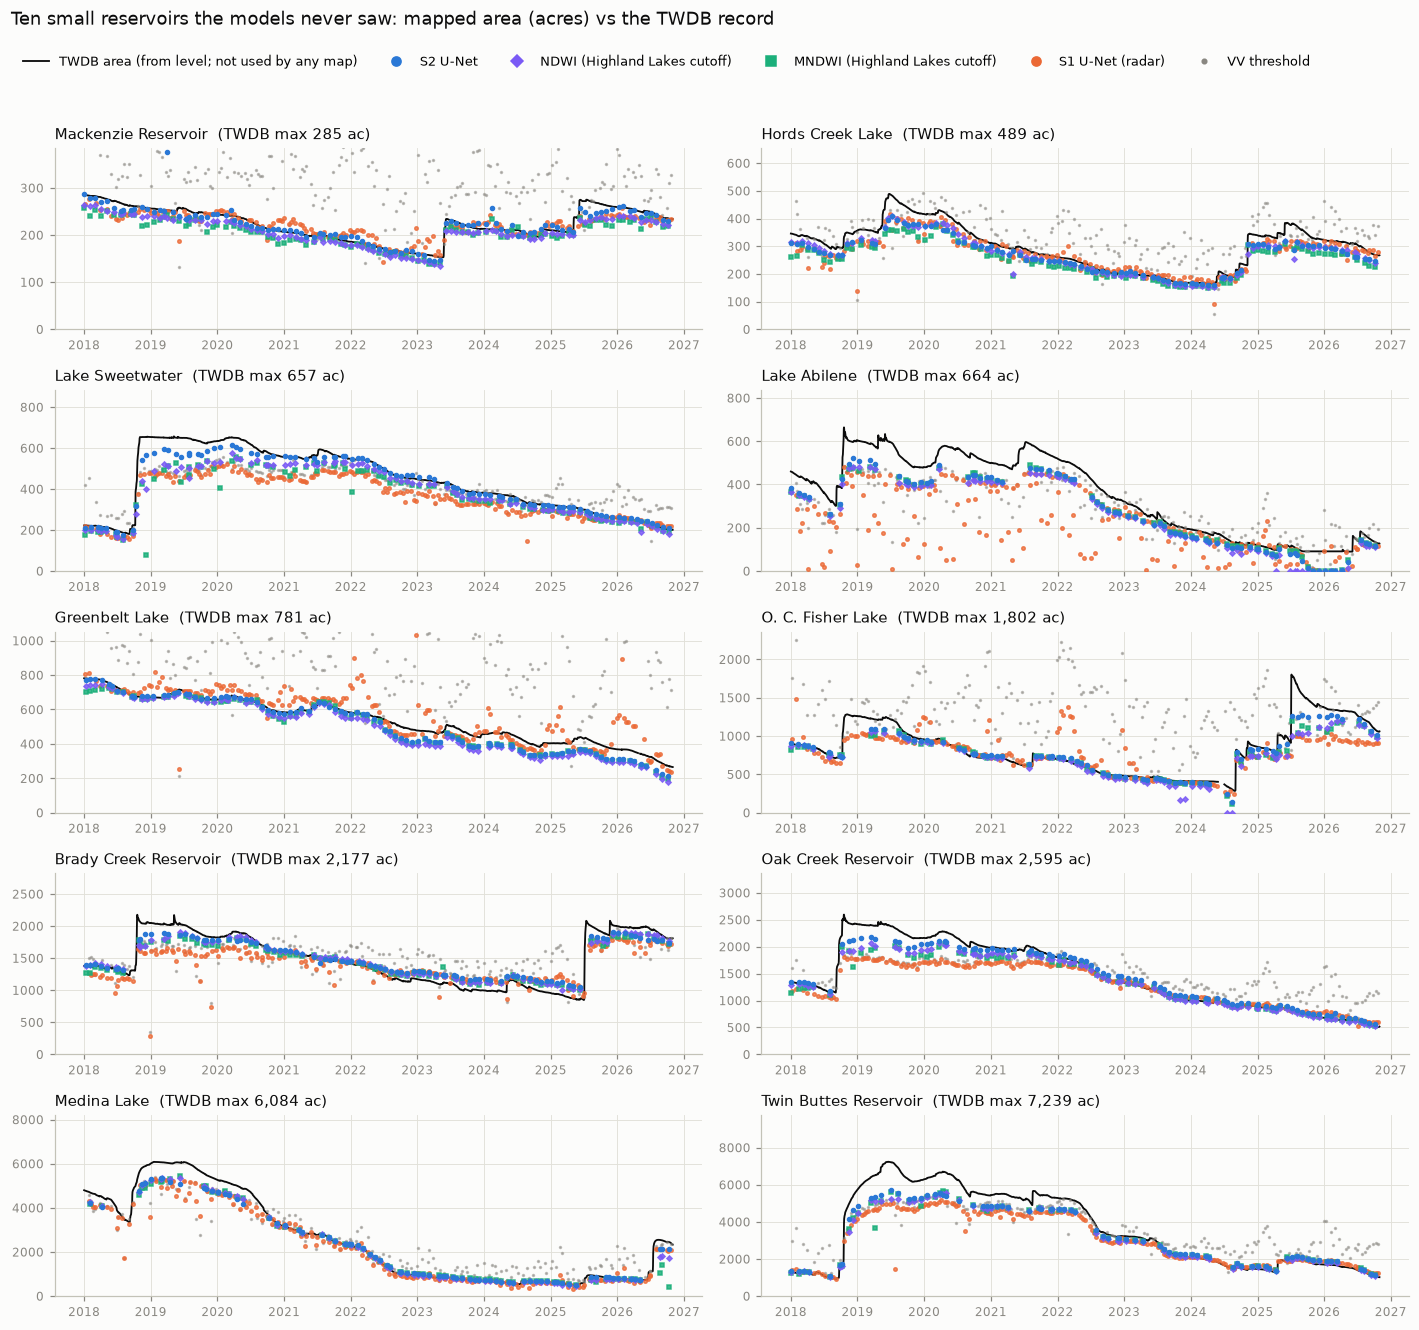

In [3]:
display(Image(filename=str(C.RESULTS_DIR / "transfer" / "transfer_timeseries.png"), width=1100))

## The numbers

For each lake and method: the median absolute error against TWDB's area on the same day, as a
percentage. Clear optical dates (one per month) and radar dates (two per month).

In [4]:
m = pd.read_csv(C.RESULTS_DIR / "transfer" / "metrics.csv")
order = list(sites.lake)
err = m.pivot_table(index="name", columns="method", values="median_abs_pct_err").reindex(order)
cols = ["S2 U-Net", "NDWI (HL cutoff)", "NDWI (Otsu)", "MNDWI (HL cutoff)", "MNDWI (Otsu)",
        "SCL water", "S1 U-Net", "VV (HL cutoff)", "VV (Otsu)"]
err = err[[c for c in cols if c in err]]
err.loc["median of lakes"] = err.median()
err.round(1)

method,S2 U-Net,NDWI (HL cutoff),NDWI (Otsu),MNDWI (HL cutoff),MNDWI (Otsu),SCL water,S1 U-Net,VV (HL cutoff),VV (Otsu)
name,,,,,,,,,
Mackenzie Reservoir,2.3,6.4,10.5,7.0,17.3,7.7,4.7,38.7,39.4
Hords Creek Lake,8.9,8.3,10.1,14.4,18.8,14.5,7.8,16.4,14.4
Lake Sweetwater,2.3,7.5,8.5,9.8,17.2,12.6,16.7,14.5,17.1
Lake Abilene,17.7,20.8,20.3,16.8,21.6,30.5,27.0,21.3,21.8
Greenbelt Lake,3.5,8.7,10.1,9.2,14.0,4.6,8.0,64.2,29.1
O. C. Fisher Lake,4.4,7.6,6.7,6.3,10.7,5.6,12.6,70.4,52.1
Brady Creek Reservoir,6.3,6.0,6.6,7.0,6.2,10.1,11.4,13.9,12.6
Oak Creek Reservoir,5.8,1.9,4.2,2.8,9.2,16.6,8.8,21.0,19.1
Medina Lake,6.2,3.1,3.0,7.0,7.7,12.4,10.5,17.2,25.6


In [5]:
e_ = err.drop("median of lakes")
for a, b in (("S2 U-Net", "NDWI (HL cutoff)"), ("S2 U-Net", "MNDWI (HL cutoff)"),
             ("S1 U-Net", "VV (HL cutoff)")):
    print(f"{a} lower error than {b} on {(e_[a] < e_[b]).sum()} of {len(e_)} lakes")

bias = m.pivot_table(index="name", columns="method", values="median_bias_pct").reindex(order)
bias = bias[[c for c in cols if c in bias]]
print("\nmedian signed error (%), negative = maps less water than TWDB:")
bias.round(1)

S2 U-Net lower error than NDWI (HL cutoff) on 5 of 10 lakes
S2 U-Net lower error than MNDWI (HL cutoff) on 7 of 10 lakes
S1 U-Net lower error than VV (HL cutoff) on 8 of 10 lakes

median signed error (%), negative = maps less water than TWDB:


method,S2 U-Net,NDWI (HL cutoff),NDWI (Otsu),MNDWI (HL cutoff),MNDWI (Otsu),SCL water,S1 U-Net,VV (HL cutoff),VV (Otsu)
name,,,,,,,,,
Mackenzie Reservoir,-0.8,-6.4,-10.5,-7.0,-17.3,-7.7,-0.4,38.6,39.4
Hords Creek Lake,-8.9,-8.3,-10.1,-14.4,-18.8,-14.5,-6.8,12.5,8.3
Lake Sweetwater,-1.6,-7.5,-8.5,-9.8,-17.2,-12.6,-16.7,-7.1,-10.5
Lake Abilene,-17.7,-20.8,-19.0,-16.8,-21.1,-30.5,-26.3,-15.6,-8.5
Greenbelt Lake,-3.5,-8.7,-10.1,-9.2,-14.0,-1.1,4.4,63.5,29.1
O. C. Fisher Lake,-2.6,-7.6,-6.4,-6.1,-10.7,-2.3,-6.3,70.4,52.1
Brady Creek Reservoir,1.2,2.5,1.0,-0.8,-5.4,-9.7,-5.2,3.5,0.1
Oak Creek Reservoir,4.2,-1.9,-3.9,-2.0,-9.2,-16.6,-3.6,6.3,1.8
Medina Lake,2.4,0.7,-1.6,1.3,-7.7,5.0,-10.2,5.2,25.6


### Is the difference more than noise?

Ten lakes is a small sample, so we ask a simple, distribution-free question: on how many lakes
does each method have the lower error, and how surprising would that split be if the two
methods were equally good (a sign test)? Then the same for each lake's dates, paired by date.

In [6]:
from math import comb


def sign_test(k, n):
    """Two-sided exact sign test: P(a split at least this lopsided | p = 0.5)."""
    tail = sum(comb(n, i) for i in range(max(k, n - k), n + 1)) / 2 ** n
    return min(1.0, 2 * tail)


for a, b in (("S2 U-Net", "NDWI (HL cutoff)"), ("S2 U-Net", "NDWI (Otsu)"),
             ("S2 U-Net", "MNDWI (HL cutoff)"), ("S2 U-Net", "MNDWI (Otsu)"),
             ("S1 U-Net", "VV (HL cutoff)"), ("S1 U-Net", "S2 U-Net")):
    e = err.drop("median of lakes")
    k = int((e[a] < e[b]).sum())
    print(f"{a} better than {b}: {k}/{len(e)} lakes, sign-test p = {sign_test(k, len(e)):.3f}")

S2 U-Net better than NDWI (HL cutoff): 5/10 lakes, sign-test p = 1.000
S2 U-Net better than NDWI (Otsu): 7/10 lakes, sign-test p = 0.344
S2 U-Net better than MNDWI (HL cutoff): 7/10 lakes, sign-test p = 0.344
S2 U-Net better than MNDWI (Otsu): 8/10 lakes, sign-test p = 0.109
S1 U-Net better than VV (HL cutoff): 8/10 lakes, sign-test p = 0.109
S1 U-Net better than S2 U-Net: 1/10 lakes, sign-test p = 0.021


Part of the U-Net's lower raw error could come from it simply mapping *more* water: every
method under-maps relative to TWDB, so the one that maps most looks best. The error left after
a per-lake linear fit removes any constant offset or scale difference and asks only how
faithfully each method tracks the ups and downs. (That fit needs a gauge, so it's a diagnostic
here, not something an ungauged user could do.)

In [7]:
fit = m.pivot_table(index="name", columns="method", values="rmse_after_fit_pct").reindex(order)
for b in ("NDWI (HL cutoff)", "MNDWI (HL cutoff)"):
    k = int((fit["S2 U-Net"] < fit[b]).sum())
    print(f"after a linear fit, S2 U-Net tracks better than {b} on {k}/10 lakes "
          f"(sign-test p = {sign_test(k, 10):.3f}); median {fit['S2 U-Net'].median():.1f} % vs "
          f"{fit[b].median():.1f} %")
fit[["S2 U-Net", "NDWI (HL cutoff)", "MNDWI (HL cutoff)", "MNDWI (Otsu)", "S1 U-Net",
     "VV (HL cutoff)"]].round(1)

after a linear fit, S2 U-Net tracks better than NDWI (HL cutoff) on 8/10 lakes (sign-test p = 0.109); median 5.6 % vs 6.8 %
after a linear fit, S2 U-Net tracks better than MNDWI (HL cutoff) on 9/10 lakes (sign-test p = 0.021); median 5.6 % vs 7.7 %


method,S2 U-Net,NDWI (HL cutoff),MNDWI (HL cutoff),MNDWI (Otsu),S1 U-Net,VV (HL cutoff)
name,,,,,,
Mackenzie Reservoir,6.7,3.0,4.9,5.6,7.7,15.0
Hords Creek Lake,4.0,5.3,5.4,6.2,10.0,21.3
Lake Sweetwater,5.4,10.1,16.5,11.7,8.3,15.4
Lake Abilene,6.5,7.8,7.3,28.5,36.6,26.6
Greenbelt Lake,2.4,2.4,3.1,3.6,13.8,22.7
O. C. Fisher Lake,9.8,17.1,13.4,13.3,27.3,38.7
Brady Creek Reservoir,3.1,4.8,4.4,5.3,16.1,21.4
Oak Creek Reservoir,5.8,6.6,8.2,10.8,10.3,21.5
Medina Lake,6.7,8.0,15.7,6.7,26.5,34.1


In [8]:
rows = []
for k, lake in L.items():
    df = transfer.joined(k)
    s2 = df[(df.sensor == "s2") & (df.kind == "clear")].dropna(subset=["twdb_area"])
    eu = (s2.area_model - s2.twdb_area).abs()
    en = (s2.area_ndwi_hl - s2.twdb_area).abs()
    em = (s2.area_mndwi_hl - s2.twdb_area).abs()
    rows.append({"lake": lake.name, "dates": len(s2),
                 "U-Net closer than NDWI, % of dates": 100 * (eu < en).mean(),
                 "U-Net closer than MNDWI, % of dates": 100 * (eu < em).mean()})
pd.DataFrame(rows).set_index("lake").reindex(order).round(0)

,dates,"U-Net closer than NDWI, % of dates","U-Net closer than MNDWI, % of dates"
lake,,,
Mackenzie Reservoir,106,84.0,87.0
Hords Creek Lake,104,49.0,94.0
Lake Sweetwater,98,100.0,96.0
Lake Abilene,85,94.0,36.0
Greenbelt Lake,104,91.0,78.0
O. C. Fisher Lake,85,76.0,73.0
Brady Creek Reservoir,99,41.0,45.0
Oak Creek Reservoir,95,39.0,45.0
Medina Lake,81,26.0,51.0


## Error against size

The practical question for an ungauged reservoir is: **how small can it be before the map stops
being useful?**

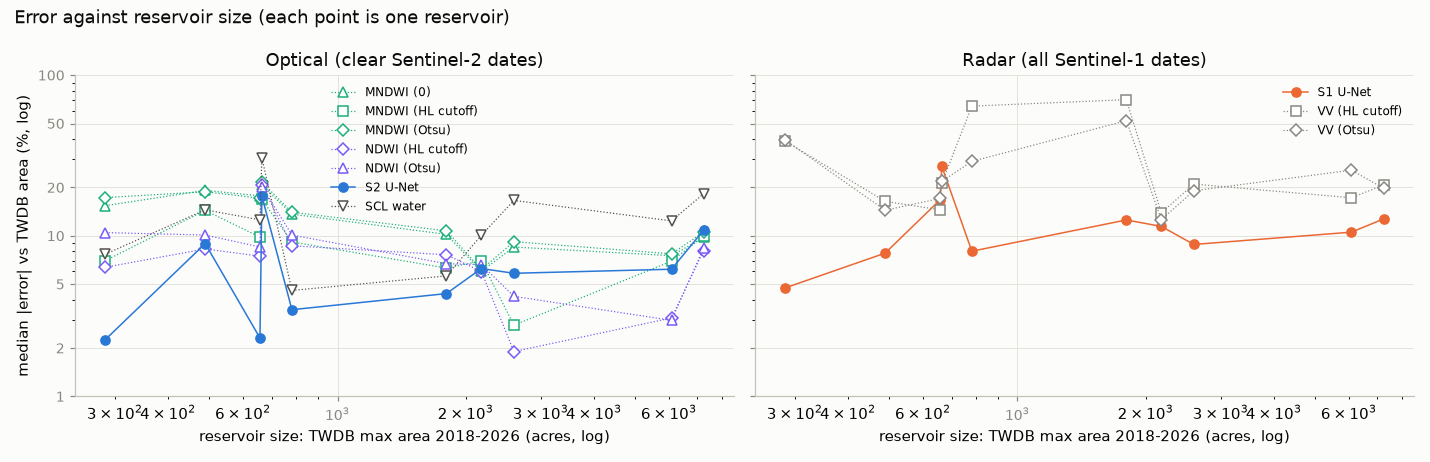

In [9]:
display(Image(filename=str(C.RESULTS_DIR / "transfer" / "transfer_error_vs_size.png"), width=1100))

## Clouds and coverage

In [10]:
cov = pd.read_csv(C.RESULTS_DIR / "transfer" / "coverage.csv")
cl = pd.read_csv(C.RESULTS_DIR / "transfer" / "cloudy.csv")
print("months with a usable map, median over lakes:",
      f"clear S2 only {cov.s2_clear_pct.median():.0f} %, S2 + S1 {cov.s2_or_s1_pct.median():.0f} %")
print("sampled cloudy S2 dates, median |error|:",
      f"clouds left in {cl.s2_cloud_in_pct.abs().median():.0f} %,",
      f"clouds masked {cl.s2_masked_pct.abs().median():.0f} %,",
      f"S1 U-Net within 3 days {cl.s1_pct.abs().median():.0f} %")

months with a usable map, median over lakes: clear S2 only 91 %, S2 + S1 100 %
sampled cloudy S2 dates, median |error|: clouds left in 18 %, clouds masked 46 %, S1 U-Net within 3 days 9 %


## Summary file

In [11]:
print(json.dumps(json.loads((C.RESULTS_DIR / "transfer" / "summary.json").read_text()), indent=1)[:3000])

{
 "cutoffs_from_highland_lakes": {
  "ndwi": -0.02499999999999991,
  "mndwi": -0.13999999999999996,
  "vv": -14.200000000000001
 },
 "median_by_method": [
  {
   "sensor": "s1",
   "method": "S1 U-Net",
   "r": 0.894,
   "median_abs_pct_err": 10.987,
   "median_bias_pct": -6.525,
   "rmse_after_fit_pct": 13.915,
   "swing_tracked": 0.916
  },
  {
   "sensor": "s1",
   "method": "VV (HL cutoff)",
   "r": 0.735,
   "median_abs_pct_err": 20.864,
   "median_bias_pct": 5.736,
   "rmse_after_fit_pct": 22.102,
   "swing_tracked": 1.1
  },
  {
   "sensor": "s1",
   "method": "VV (Otsu)",
   "r": 0.636,
   "median_abs_pct_err": 20.787,
   "median_bias_pct": 5.057,
   "rmse_after_fit_pct": 23.047,
   "swing_tracked": 0.768
  },
  {
   "sensor": "s2",
   "method": "MNDWI (0)",
   "r": 0.975,
   "median_abs_pct_err": 11.925,
   "median_bias_pct": -11.925,
   "rmse_after_fit_pct": 8.62,
   "swing_tracked": 0.803
  },
  {
   "sensor": "s2",
   "method": "MNDWI (HL cutoff)",
   "r": 0.982,
   "media

## What this does and doesn't show

**On small reservoirs it has never seen, the S2 U-Net is a little more accurate than the best
index, and clearly more accurate than MNDWI.**

* **Raw error** (what an ungauged user gets): median 6.0 % across lakes for the U-Net, 7.5 %
  for NDWI with the Highland Lakes cutoff and 8.1 % for MNDWI. Against NDWI that's a split, 5
  lakes each, and against MNDWI the U-Net is lower on 7 of 10.
* **Size decides it.** On the five smallest reservoirs (all under 800 acres), the U-Net is
  closer to TWDB than NDWI on most dates (84-100 % of dates, apart from Hords Creek at 49 %).
  On the four largest, NDWI is closer on most dates. NDWI's bias grows as lakes shrink: it
  maps 6-9 % less water than TWDB on most small lakes, while the U-Net's median bias is within
  ±5 % on eight of the ten. A fringe of mixed shoreline pixels is a bigger share of a small
  lake, and the U-Net counts more of it as water.
* **Tracking** (after a per-lake linear fit, which removes any constant offset): the U-Net is
  better than NDWI on 8 of 10 lakes (p = 0.11, median 5.6 % vs 6.8 %) and better than MNDWI on
  9 of 10 (p = 0.02).
* **Turbid floodwater**: after the July 2026 refill of Medina, with TWDB at about 2,500 acres,
  MNDWI mapped 400-1,400 acres, NDWI about 1,750 and the U-Net about 2,140. Sediment-laden
  water is where the model's extra bands and context still pay.

So the model's advantage here is real but modest, and it lives on the smallest lakes and the
muddiest water: exactly where a single cutoff tuned on big clear lakes fits worst. (With cutoffs
tuned on the AI labels instead, the gap over MNDWI is bigger; the cutoff tuned on the person's
labels helps MNDWI considerably.)

**Radar:** the S1 U-Net beats the VV threshold on 8 of 10 lakes (median 11 % vs 21 % error),
and radar fills every month (clear optical alone: a median of 91 % of months). But radar is
**noticeably weaker on small lakes** than on the Highland Lakes: correlation with TWDB area is
0.71-0.97 here against 0.99 at Travis and Buchanan, and it is the worse sensor on 9 of 10
lakes. Use clear optical dates when you have them, and radar to fill the gaps.

**What doesn't work, or isn't shown:**

* **Lake Abilene** fails for every method (18-31 % low). The gap is at high water, when TWDB's
  area runs far above anything visible. That points at flooded vegetation or the rating curve,
  not at one method, but we can't tell which.
* **Everyone under-maps high water.** On six of the ten lakes the U-Net's mapped swing (max −
  min) is only 68-87 % of TWDB's, because it falls short at high water (e.g. Sweetwater, Oak
  Creek and Twin Buttes in 2019). The indices and radar fall about as short. The same 5-15 %
  full-pool shortfall appeared on the Highland Lakes. Satellite area should be read as "open water visible at 10 m", not as rating-curve area.
* **Still a regional test.** Ten reservoirs, all in West/Central Texas, all scored against TWDB
  areas that come from rating curves rather than measurements. A truly ungauged pond or stock
  tank is smaller still (often under a few acres). Notebook 9 tests those, and the answer is
  different.

**Practical reading:** for a reservoir of a few hundred acres or more with no gauge, the
shipped S2 model (`hlw infer`) gives a monthly area series typically within about 5-10 % of what
a gauge plus rating curve would say, with no tuning. NDWI with a cutoff near zero is almost as
good, and better on the larger lakes; it under-counts the smallest ones by a few percent more
and struggles with muddy floodwater. The S1 model fills cloudy months at roughly twice the
optical error.